# Credit Card Fraud Detection — Data Cleaning & Exploratory Data Analysis

**Level:** Basic to Intermediate  
**Platform:** Kaggle Notebook  
**Libraries:** Pandas, NumPy, Matplotlib

This notebook prepares and explores the credit-card transaction dataset. It is written in small steps with beginner-friendly explanations.

## Notebook roadmap

1. Import Python libraries.
2. Load the CSV from Kaggle.
3. Understand rows, columns and data types.
4. Check missing values and duplicate transactions.
5. Clean text, numeric, binary and date fields.
6. Handle missing browser values correctly.
7. Validate important business fields and outliers.
8. Create useful time and risk-analysis features.
9. Explore fraud vs legitimate transactions.
10. Analyse fraud by time, amount, merchant, country, channel, device and authentication.
11. Explore customer/account and transaction-velocity patterns.
12. Review fraud types and fraud-labelled amount fields.
13. Check correlations.
14. Export the cleaned data and EDA summary tables.

**Important:** The dataset profile describes synthetic transactions and a synthetic fraud label. Results are useful for learning and portfolio analysis, but they are not evidence of real bank fraud performance.

## Step 1 — Import libraries

We use Pandas for data handling, NumPy for numeric operations, and Matplotlib for charts. We keep the library set small so the notebook is easy to follow.

In [41]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2 — Find and load the dataset

First use Kaggle's **Add Input** button to attach the dataset to this notebook.

The code searches `/kaggle/input` for CSV files. If only one CSV is attached, it loads it automatically. If several CSV files are found, copy the correct path from the output and paste it into `DATA_PATH`.

In [42]:
# Keep this blank when only one CSV is attached to the notebook.
DATA_PATH = ""

csv_files = glob.glob("/kaggle/input/datasets/mohankrishnathalla/credit-card-fraud-detection-dataset-2026/credit_card_fraud_detection_2026.csv", recursive=True)

print("CSV files found:")
for file in csv_files:
    print(file)

if DATA_PATH == "":
    if len(csv_files) == 1:
        DATA_PATH = csv_files[0]
    elif len(csv_files) == 0:
        raise FileNotFoundError(
            "No CSV found. Click Add Input in Kaggle and attach your dataset."
        )
    else:
        raise ValueError(
            "More than one CSV was found. Copy the correct file path above into DATA_PATH."
        )

df = pd.read_csv(DATA_PATH, low_memory=False)

print("\nDataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

CSV files found:
/kaggle/input/datasets/mohankrishnathalla/credit-card-fraud-detection-dataset-2026/credit_card_fraud_detection_2026.csv

Dataset loaded successfully.
Rows: 100000
Columns: 43


## Step 3 — Understand the dataset

Check the first five rows, the last five rows, all column names and data types.

The identifier columns (`transaction_id`, `customer_id`, `card_id`, and `merchant_id`) identify records/entities. They should not be treated as continuous numeric measures, even if they look numeric.

In [43]:
display(df.head())
display(df.tail())

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_state,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.360,Healthcare & Pharmacy,USA,2,Monday,0,41,Female,PA,709,"6,630.000",742,2,1,2,3,88.910,209.940,0.900,13.000,0.300,0,0,0.398,0,0,Online,Mobile,Chrome,0,93.910,39.480,0,0,corporate,0,Legitimate,0.000
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.040,Restaurant & Dining,Germany,3,Monday,1,56,Male,WV,1143,"4,350.000",602,1,6,6,23,"1,290.100","1,093.310",6.600,"5,311.800",17.000,1,0,0.278,1,1,In-store,POS Terminal,NaN,0,180.050,134.450,0,0,yahoo,0,Legitimate,0.000
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.870,Grocery & Supermarket,Australia,3,Monday,0,43,Male,MN,601,"3,950.000",605,4,1,1,3,36.270,46.540,4.200,"14,164.500",53.200,1,0,0.925,0,0,Online,Desktop,Chrome,0,42.000,22.460,0,0,hotmail,0,Legitimate,0.000
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.600,Gas Station,China,3,Monday,0,51,Female,OH,582,"13,870.000",675,5,0,2,3,0.000,134.350,3.000,"1,119.100",3.600,1,1,0.718,0,1,ATM,ATM,NaN,0,64.870,29.760,0,0,gmail,0,Legitimate,0.000
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.130,Clothing & Apparel,UK,4,Monday,1,40,Female,PA,711,"6,570.000",743,2,1,2,2,38.370,117.740,0.900,"6,564.500",22.400,1,0,1.317,1,0,In-store,POS Terminal,NaN,0,47.190,18.520,0,0,gmail,0,Legitimate,0.000


,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_state,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost
99995,TXN-00099996,CUS-00006390,CRD-00006390,MER-00000996,2026-12-31 23:21:36,32.830,Restaurant & Dining,Italy,23,Tuesday,1,48,Female,FL,19,"8,490.000",588,3,0,1,7,0.000,88.900,4.800,"11,870.800",2.300,1,0,0.340,1,0,In-store,POS Terminal,NaN,0,96.520,44.550,0,0,gmail,0,Legitimate,0.000
99996,TXN-00099997,CUS-00006126,CRD-00006126,MER-00001056,2026-12-31 23:26:09,167.720,Electronics & Technology,Spain,23,Tuesday,0,20,Female,UT,49,"2,750.000",479,5,0,1,19,0.000,75.380,13.100,"3,630.800",0.200,1,0,2.214,0,1,ATM,ATM,NaN,0,75.740,41.670,0,2,gmail,0,Legitimate,0.000
99997,TXN-00099998,CUS-00004651,CRD-00004651,MER-00002493,2026-12-31 23:30:16,"1,031.100",Travel & Airlines,France,23,Tuesday,0,28,Female,NM,639,"11,630.000",712,2,3,4,7,148.760,194.290,2.400,"13,186.000",1.400,1,0,22.711,0,0,Mobile App,Mobile,App,0,45.400,35.110,2,4,gmail,1,Card-Not-Present,"1,012.060"
99998,TXN-00099999,CUS-00007845,CRD-00007845,MER-00002563,2026-12-31 23:31:19,81.750,Clothing & Apparel,UK,23,Tuesday,0,56,Male,NE,89,"5,050.000",567,4,0,0,6,0.000,0.000,0.800,"2,059.800",14.300,1,0,0.486,0,0,Mobile App,Mobile,App,0,168.240,81.400,0,0,yahoo,0,Legitimate,0.000
99999,TXN-00100000,CUS-00002752,CRD-00002752,MER-00001618,2026-12-31 23:45:47,48.460,Restaurant & Dining,India,23,Tuesday,1,36,Female,MO,110,"5,440.000",540,2,0,0,1,0.000,0.000,1.700,"7,698.100",3.900,1,0,0.419,1,1,In-store,POS Terminal,NaN,0,115.620,64.300,0,0,gmail,0,Legitimate,0.000


Dataset shape: (100000, 43)

Column names:
['transaction_id', 'customer_id', 'card_id', 'merchant_id', 'transaction_datetime', 'transaction_amount', 'merchant_category', 'merchant_country', 'transaction_hour', 'transaction_day_of_week', 'card_present', 'customer_age', 'customer_gender', 'customer_state', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'is_weekend', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'email_domain', 'is_fraud', 'fraud_type', 'fraud_amount_lost']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data co

## Step 4 — Compare the actual schema with the expected fields

This is a schema check. It helps identify missing or additional columns before analysis. It does not create missing fields or invent data.

In [44]:
expected_columns = ['transaction_id', 'customer_id', 'card_id', 'merchant_id', 'transaction_datetime', 'transaction_amount', 'merchant_category', 'merchant_country', 'transaction_hour', 'transaction_day_of_week', 'card_present', 'customer_age', 'customer_gender', 'customer_state', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'is_weekend', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'email_domain', 'is_fraud', 'fraud_type', 'fraud_amount_lost']

actual_columns = df.columns.tolist()

missing_columns = [col for col in expected_columns if col not in actual_columns]
extra_columns = [col for col in actual_columns if col not in expected_columns]

print("Expected columns:", len(expected_columns))
print("Actual columns:", len(actual_columns))
print("Missing expected columns:", missing_columns)
print("Additional columns:", extra_columns)

Expected columns: 43
Actual columns: 43
Missing expected columns: []
Additional columns: []


## Step 5 — Check missing values

Your supplied profile reports 41,709 missing values in `browser` and zero missing values in the other listed columns.

Run this step against the actual CSV to confirm those counts. A profile summary and the raw file should agree before we publish the data-quality result.

In [45]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().sum() / len(df)) * 100
}).sort_values("missing_count", ascending=False)

display(missing_report)

print("Total missing cells:", int(df.isna().sum().sum()))
print("Columns with missing values:", int((df.isna().sum() > 0).sum()))

,missing_count,missing_percent
browser,41709,41.709
customer_id,0,0.000
transaction_id,0,0.000
merchant_id,0,0.000
transaction_datetime,0,0.000
transaction_amount,0,0.000
merchant_category,0,0.000
merchant_country,0,0.000
transaction_hour,0,0.000
transaction_day_of_week,0,0.000


Total missing cells: 41709
Columns with missing values: 1


## Step 6 — Check duplicate records and transaction IDs

We check exact duplicate rows and duplicate transaction IDs separately.

**Important:** Do not delete duplicate transaction IDs automatically. First inspect them. The transaction ID is expected to uniquely identify a transaction, so repeated IDs should be investigated before deciding which record is correct.

In [46]:
print("Exact duplicate rows:", df.duplicated().sum())

if "transaction_id" in df.columns:
    print("Duplicate transaction IDs:", df["transaction_id"].duplicated().sum())

    duplicate_transactions = (
        df[df.duplicated(subset="transaction_id", keep=False)]
        .sort_values("transaction_id")
    )
    display(duplicate_transactions.head(20))
else:
    duplicate_transactions = pd.DataFrame()
    print("transaction_id column is not available.")

Exact duplicate rows: 0
Duplicate transaction IDs: 0


,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_state,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost


## Step 7 — Create a working copy and clean column names

We keep the original `df` unchanged and make a separate `clean_df` for analysis.

Column names are converted to lowercase, and extra spaces are removed.

In [47]:
clean_df = df.copy()

clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Remove exact duplicate rows only.
rows_before = len(clean_df)
clean_df = clean_df.drop_duplicates()
print("Exact duplicate rows removed:", rows_before - len(clean_df))
print("Working dataset shape:", clean_df.shape)

Exact duplicate rows removed: 0
Working dataset shape: (100000, 43)


## Step 8 — Clean text columns

Remove leading/trailing spaces and convert blank text values to missing values.

We do not fill all text fields with the same value yet, because `browser` needs special treatment in the next step.

In [48]:
text_columns = clean_df.select_dtypes(include=["object", "string"]).columns.tolist()

for column in text_columns:
    clean_df[column] = clean_df[column].astype("string").str.strip()
    clean_df[column] = clean_df[column].replace("", pd.NA)

print("Text cleaning completed.")

Text cleaning completed.


## Step 9 — Convert numeric columns

Convert the numeric fields to numbers. Any value that cannot be converted becomes missing (`NaN`) so it can be reviewed in the data-quality report.

Identifier columns are kept as text to avoid treating IDs as numerical measurements.

In [49]:
id_columns = [
    "transaction_id", "customer_id", "card_id", "merchant_id"
]

numeric_columns = [
    "transaction_amount", "transaction_hour", "card_present",
    "customer_age", "account_age_days", "credit_limit", "credit_score",
    "num_cards_held", "transactions_last_1h", "transactions_last_24h",
    "transactions_last_7d", "amount_last_1h", "amount_last_24h",
    "days_since_last_transaction", "distance_from_home_km",
    "distance_from_last_tx_km", "international_transaction",
    "high_risk_country", "amount_vs_avg_ratio", "used_chip", "used_pin",
    "is_weekend", "avg_transaction_amount_30d", "std_transaction_amount_30d",
    "num_declined_last_30d", "num_chargebacks_ever", "is_fraud",
    "fraud_amount_lost"
]

for column in id_columns:
    if column in clean_df.columns:
        clean_df[column] = clean_df[column].astype("string").str.strip()

for column in numeric_columns:
    if column in clean_df.columns:
        clean_df[column] = pd.to_numeric(clean_df[column], errors="coerce")

print("Numeric conversion completed.")

Numeric conversion completed.


## Step 10 — Convert transaction date and create time features

Convert `transaction_datetime` into a true datetime column. Then create year, month, date, hour and day-name fields from the timestamp.

These derived fields make time-based EDA easier. The original `transaction_hour` and `transaction_day_of_week` fields are retained so we can compare them with the timestamp-derived values.

In [50]:
if "transaction_datetime" in clean_df.columns:
    clean_df["transaction_datetime"] = pd.to_datetime(
        clean_df["transaction_datetime"],
        errors="coerce"
    )

    clean_df["transaction_year"] = clean_df["transaction_datetime"].dt.year
    clean_df["transaction_month"] = clean_df["transaction_datetime"].dt.month
    clean_df["transaction_month_name"] = clean_df["transaction_datetime"].dt.strftime("%b")
    clean_df["transaction_date"] = clean_df["transaction_datetime"].dt.date
    clean_df["transaction_hour_from_datetime"] = clean_df["transaction_datetime"].dt.hour
    clean_df["transaction_day_name_from_datetime"] = (
        clean_df["transaction_datetime"].dt.day_name()
    )

    print("Minimum transaction date:", clean_df["transaction_datetime"].min())
    print("Maximum transaction date:", clean_df["transaction_datetime"].max())
    print("Invalid transaction dates:", clean_df["transaction_datetime"].isna().sum())

Minimum transaction date: 2026-01-01 02:28:51
Maximum transaction date: 2026-12-31 23:45:47
Invalid transaction dates: 0


## Step 11 — Handle missing browser values

Your profile says `browser` is not applicable for some in-store and ATM transactions. Therefore, we should not label every missing browser value as a data error.

The cleaning rule is:
- For in-store and ATM transactions with no browser, use `Not Applicable`.
- For other channels with no browser recorded, use `Unknown`.
- Keep actual browser names such as Chrome, Safari, Firefox or App.

We will print the missing count before and after cleaning.

In [51]:
if "browser" in clean_df.columns:
    print("Missing browser values before:", clean_df["browser"].isna().sum())

    channel_lower = clean_df["transaction_channel"].astype("string").str.lower()

    not_applicable_channels = channel_lower.str.contains(
        "in.store|atm", regex=True, na=False
    )

    clean_df.loc[
        clean_df["browser"].isna() & not_applicable_channels,
        "browser"
    ] = "Not Applicable"

    clean_df["browser"] = clean_df["browser"].fillna("Unknown")

    print("Missing browser values after:", clean_df["browser"].isna().sum())
    print("\nBrowser values:")
    display(clean_df["browser"].value_counts(dropna=False))
else:
    print("browser column not found.")

Missing browser values before: 41709
Missing browser values after: 0

Browser values:


browser
Not Applicable    41709
Chrome            20359
Safari            12841
App               12759
Firefox            5448
Edge               4544
Other              2340
Name: count, dtype: Int64

## Step 12 — Handle missing values in other columns

The supplied profile shows no missing values outside `browser`. This cell checks the actual file.

- Missing categorical values are labelled `Unknown`.
- Missing numeric values are left as missing rather than filled with zero or an average.
- If numeric missing values exist, we will inspect them before deciding how to handle them.

In [52]:
categorical_columns = clean_df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

for column in categorical_columns:
    if column != "browser":
        clean_df[column] = clean_df[column].fillna("Unknown")

missing_after_cleaning = pd.DataFrame({
    "missing_count": clean_df.isna().sum(),
    "missing_percent": (clean_df.isna().sum() / len(clean_df)) * 100
}).sort_values("missing_count", ascending=False)

display(missing_after_cleaning[missing_after_cleaning["missing_count"] > 0])

print("Total missing cells after cleaning:", int(clean_df.isna().sum().sum()))

,missing_count,missing_percent


Total missing cells after cleaning: 0


## Step 13 — Validate binary fields

These columns are expected to contain 0 or 1:
- `card_present`
- `international_transaction`
- `high_risk_country`
- `used_chip`
- `used_pin`
- `is_weekend`
- `is_fraud`

This step reports unexpected values without silently changing them.

In [53]:
binary_columns = [
    "card_present",
    "international_transaction",
    "high_risk_country",
    "used_chip",
    "used_pin",
    "is_weekend",
    "is_fraud"
]

for column in binary_columns:
    if column in clean_df.columns:
        values = sorted(clean_df[column].dropna().unique().tolist())
        unexpected = [value for value in values if value not in [0, 1]]
        print(f"{column}: values={values}, unexpected={unexpected}")

card_present: values=[0, 1], unexpected=[]
international_transaction: values=[0, 1], unexpected=[]
high_risk_country: values=[0, 1], unexpected=[]
used_chip: values=[0, 1], unexpected=[]
used_pin: values=[0, 1], unexpected=[]
is_weekend: values=[0, 1], unexpected=[]
is_fraud: values=[0, 1], unexpected=[]


## Step 14 — Basic data validation and unusual values

Check key business rules:
- Transaction amount should be positive.
- Age should be within a plausible range for the dataset.
- Transaction hour should be between 0 and 23.
- Fraud target should contain only 0 and 1.
- Credit score and credit limit should be reviewed for unusual values.

We flag records for review; we do not automatically delete them.

In [54]:
validation_checks = {}

if "transaction_amount" in clean_df.columns:
    validation_checks["non_positive_transaction_amount"] = (
        clean_df["transaction_amount"] <= 0
    ).sum()

if "customer_age" in clean_df.columns:
    validation_checks["age_below_18_or_above_100"] = (
        (clean_df["customer_age"] < 18) |
        (clean_df["customer_age"] > 100)
    ).sum()

if "transaction_hour" in clean_df.columns:
    validation_checks["invalid_transaction_hour"] = (
        (clean_df["transaction_hour"] < 0) |
        (clean_df["transaction_hour"] > 23)
    ).sum()

if "is_fraud" in clean_df.columns:
    validation_checks["invalid_is_fraud_values"] = (
        ~clean_df["is_fraud"].isin([0, 1])
    ).sum()

if "credit_limit" in clean_df.columns:
    validation_checks["non_positive_credit_limit"] = (
        clean_df["credit_limit"] <= 0
    ).sum()

display(pd.DataFrame.from_dict(
    validation_checks, orient="index", columns=["records_to_review"]
))

,records_to_review
non_positive_transaction_amount,0
age_below_18_or_above_100,0
invalid_transaction_hour,0
invalid_is_fraud_values,0
non_positive_credit_limit,0


## Step 15 — Review target balance: fraud vs legitimate

This is one of the most important checks in a fraud project.

Calculate:
- Legitimate transaction count.
- Fraud transaction count.
- Fraud percentage.
- Legitimate percentage.

Do not rely on accuracy alone in a highly imbalanced fraud dataset.

In [55]:
if "is_fraud" in clean_df.columns:
    fraud_counts = clean_df["is_fraud"].value_counts().sort_index()
    fraud_summary = pd.DataFrame({
        "transaction_count": fraud_counts,
        "percentage": fraud_counts / len(clean_df) * 100
    })
    fraud_summary.index = fraud_summary.index.map({
        0: "Legitimate",
        1: "Fraud"
    })
    display(fraud_summary)

    fraud_rate = clean_df["is_fraud"].mean() * 100
    print(f"Overall fraud rate: {fraud_rate:.3f}%")

,transaction_count,percentage
is_fraud,,
Legitimate,97945,97.945
Fraud,2055,2.055


Overall fraud rate: 2.055%


## Step 16 — Descriptive statistics

Review transaction amount, credit, customer, velocity and distance fields. Transaction values may be highly skewed, so compare the median and quartiles as well as the mean.

In [56]:
numeric_data = clean_df.select_dtypes(include=np.number)

display(numeric_data.describe().T)

,count,mean,std,min,25%,50%,75%,max
transaction_amount,"100,000.000",126.872,276.180,0.500,21.280,52.260,129.720,"15,000.000"
transaction_hour,"100,000.000",14.394,5.018,0.000,11.000,14.000,19.000,23.000
card_present,"100,000.000",0.358,0.479,0.000,0.000,0.000,1.000,1.000
customer_age,"100,000.000",42.224,14.246,18.000,32.000,42.000,52.000,85.000
account_age_days,"100,000.000",785.451,747.492,1.000,233.000,554.000,"1,103.000","3,650.000"
credit_limit,"100,000.000","10,083.182","6,510.647",500.000,"5,000.000","8,500.000","13,650.000","36,670.000"
credit_score,"100,000.000",682.329,92.122,328.000,620.000,683.000,748.000,850.000
num_cards_held,"100,000.000",2.199,1.163,1.000,1.000,2.000,3.000,5.000
transactions_last_1h,"100,000.000",0.784,1.349,0.000,0.000,0.000,1.000,8.000
transactions_last_24h,"100,000.000",2.952,2.382,0.000,1.000,2.000,4.000,18.000


## Step 17 — Transaction amount distribution

First view the raw transaction amount distribution. Then view a log-scaled version to make the long tail easier to inspect.

The log chart changes the display scale, not the original transaction values.

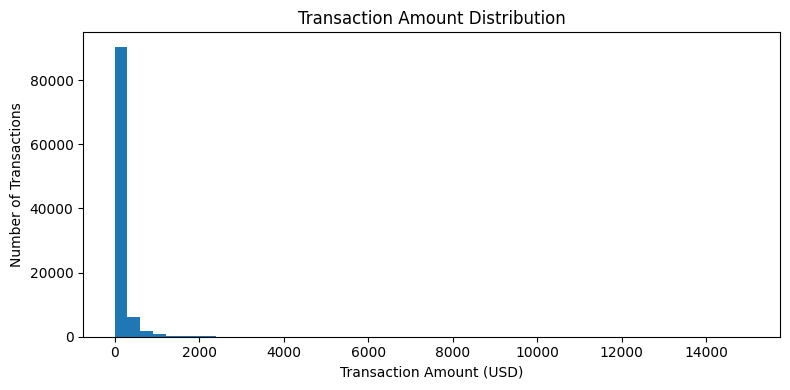

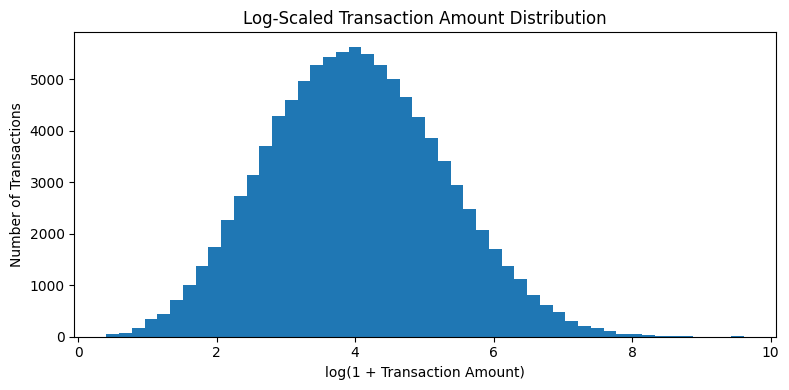

In [57]:
if "transaction_amount" in clean_df.columns:
    plt.figure(figsize=(8, 4))
    plt.hist(clean_df["transaction_amount"].dropna(), bins=50)
    plt.title("Transaction Amount Distribution")
    plt.xlabel("Transaction Amount (USD)")
    plt.ylabel("Number of Transactions")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.hist(np.log1p(clean_df["transaction_amount"].dropna()), bins=50)
    plt.title("Log-Scaled Transaction Amount Distribution")
    plt.xlabel("log(1 + Transaction Amount)")
    plt.ylabel("Number of Transactions")
    plt.tight_layout()
    plt.show()

## Step 18 — Compare fraud and legitimate transactions

Compare the number of records, average transaction amount, median transaction amount and total transaction value for each target class.

The total transaction amount for fraud-labelled records is **flagged transaction value**, not automatically confirmed financial loss.

In [58]:
fraud_vs_legitimate = clean_df.groupby("is_fraud").agg(
    transaction_count=("transaction_id", "count"),
    average_amount=("transaction_amount", "mean"),
    median_amount=("transaction_amount", "median"),
    total_transaction_amount=("transaction_amount", "sum"),
    average_credit_score=("credit_score", "mean"),
    average_account_age_days=("account_age_days", "mean")
)

fraud_vs_legitimate.index = fraud_vs_legitimate.index.map({
    0: "Legitimate",
    1: "Fraud"
})

display(fraud_vs_legitimate)

,transaction_count,average_amount,median_amount,total_transaction_amount,average_credit_score,average_account_age_days
is_fraud,,,,,,
Legitimate,97945,125.969,52.060,"12,337,988.030",682.473,788.958
Fraud,2055,169.932,64.800,"349,209.640",675.463,618.333


## Step 19 — Fraud by transaction hour

Calculate fraud rate by hour using the correct denominator: fraudulent transactions divided by all transactions in that hour.

Also show the total number of transactions in each hour, because a high rate based on a small number of transactions can be unstable.

,transaction_hour,total_transactions,fraud_transactions,fraud_rate,fraud_rate_pct
0,0,1012,27,0.027,2.668
1,1,597,50,0.084,8.375
2,2,361,27,0.075,7.479
3,3,230,26,0.113,11.304
4,4,256,20,0.078,7.812
5,5,516,9,0.017,1.744
6,6,1553,38,0.024,2.447
7,7,3159,65,0.021,2.058
8,8,4936,106,0.021,2.147
9,9,5381,90,0.017,1.673


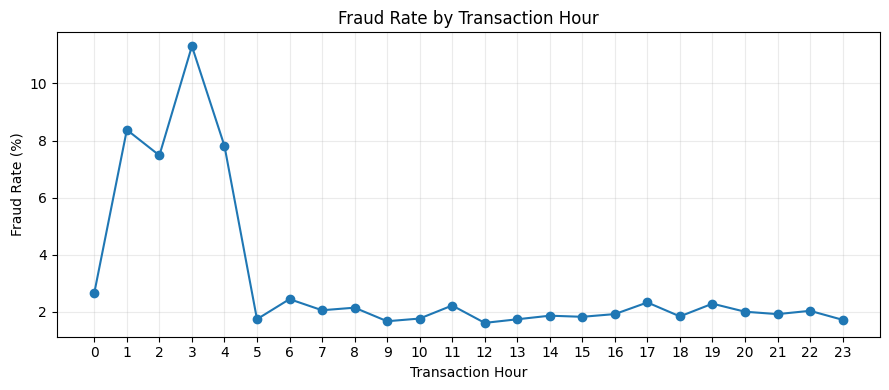

In [59]:
hour_summary = clean_df.groupby("transaction_hour").agg(
    total_transactions=("transaction_id", "count"),
    fraud_transactions=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
).reset_index()

hour_summary["fraud_rate_pct"] = hour_summary["fraud_rate"] * 100
display(hour_summary.sort_values("transaction_hour"))

plt.figure(figsize=(9, 4))
plt.plot(
    hour_summary["transaction_hour"],
    hour_summary["fraud_rate_pct"],
    marker="o"
)
plt.title("Fraud Rate by Transaction Hour")
plt.xlabel("Transaction Hour")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Step 20 — Fraud by day of week and month

Compare fraud rates across days of the week and calendar months. These are descriptive patterns in the supplied period, not seasonal proof.

,transaction_day_of_week,total_transactions,fraud_transactions,fraud_rate,fraud_rate_pct
2,Saturday,14133,317,0.022,2.243
6,Wednesday,14183,300,0.021,2.115
5,Tuesday,14507,305,0.021,2.102
4,Thursday,14317,292,0.020,2.040
0,Friday,14196,286,0.020,2.015
1,Monday,14384,279,0.019,1.940
3,Sunday,14280,276,0.019,1.933


,transaction_month,total_transactions,fraud_transactions,fraud_rate,total_amount,fraud_rate_pct
0,1,8593,191,0.022,"1,123,757.800",2.223
1,2,7928,151,0.019,"992,729.860",1.905
2,3,8445,164,0.019,"1,044,154.080",1.942
3,4,8119,156,0.019,"1,017,459.210",1.921
4,5,8295,171,0.021,"1,055,554.000",2.061
5,6,8179,153,0.019,"1,028,631.570",1.871
6,7,8435,181,0.021,"1,055,328.770",2.146
7,8,8394,174,0.021,"1,106,223.070",2.073
8,9,8275,164,0.020,"1,048,579.110",1.982
9,10,8630,198,0.023,"1,087,465.870",2.294


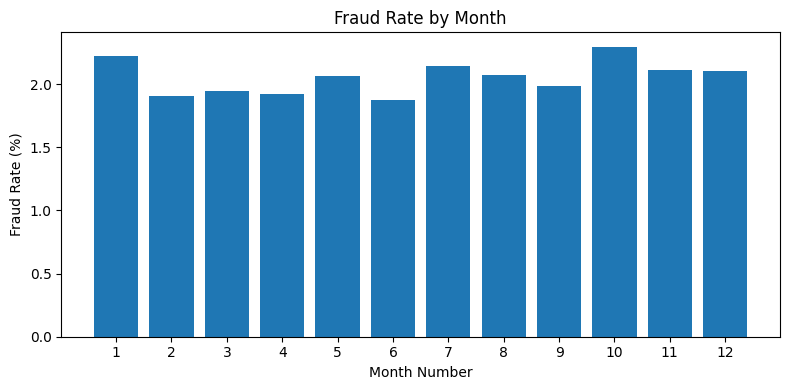

In [60]:
if "transaction_day_of_week" in clean_df.columns:
    day_summary = clean_df.groupby("transaction_day_of_week").agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    ).reset_index()
    day_summary["fraud_rate_pct"] = day_summary["fraud_rate"] * 100
    display(day_summary.sort_values("fraud_rate_pct", ascending=False))

if "transaction_month" in clean_df.columns:
    month_summary = clean_df.groupby("transaction_month").agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean"),
        total_amount=("transaction_amount", "sum")
    ).reset_index()
    month_summary["fraud_rate_pct"] = month_summary["fraud_rate"] * 100
    display(month_summary.sort_values("transaction_month"))

    plt.figure(figsize=(8, 4))
    plt.bar(month_summary["transaction_month"], month_summary["fraud_rate_pct"])
    plt.title("Fraud Rate by Month")
    plt.xlabel("Month Number")
    plt.ylabel("Fraud Rate (%)")
    plt.xticks(range(1, 13))
    plt.tight_layout()
    plt.show()

## Step 21 — Fraud by merchant category and country

For every segment, calculate:
- Number of transactions.
- Number of fraud transactions.
- Fraud rate.

This avoids ranking categories only by fraud count. Large categories naturally have more transactions, so the rate and sample size should be considered together.

,merchant_category,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
11,Online Retail,13417,446,"1,421,929.890",3.324
13,Travel & Airlines,6612,193,"2,367,322.290",2.919
4,Entertainment & Streaming,5848,146,"190,114.880",2.497
14,Utilities & Telecom,1036,24,"68,380.050",2.317
10,Hotel & Lodging,6360,133,"1,696,708.520",2.091
3,Electronics & Technology,6934,142,"1,621,795.840",2.048
9,Home Improvement,3824,74,"622,136.070",1.935
8,Healthcare & Pharmacy,7903,151,"1,166,703.720",1.911
5,Financial Services,873,16,"380,849.580",1.833
0,Auto & Transportation,3974,69,"490,562.950",1.736


,merchant_country,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
12,Romania,943,122,"135,932.650",12.937
13,Russia,1046,119,"133,766.410",11.377
11,Nigeria,1261,138,"151,583.480",10.944
3,China,1682,166,"210,615.250",9.869
15,South Korea,788,26,"102,781.070",3.299
14,South Africa,1140,37,"134,037.690",3.246
1,Brazil,2354,70,"286,656.010",2.974
2,Canada,7238,205,"920,371.290",2.832
0,Australia,5423,153,"659,809.260",2.821
4,France,4521,126,"522,936.370",2.787


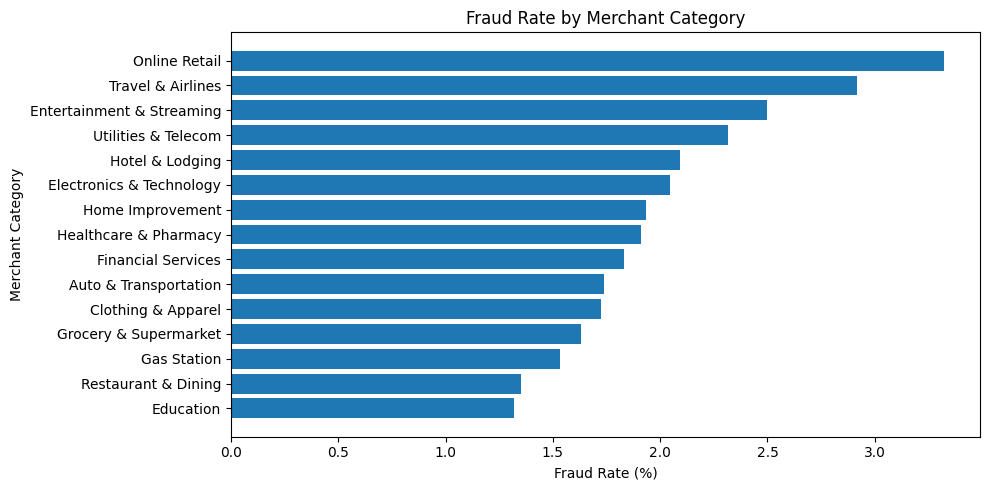

In [61]:
def fraud_segment_summary(data, group_column, min_transactions=1):
    result = data.groupby(group_column, dropna=False).agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("is_fraud", "sum"),
        total_transaction_amount=("transaction_amount", "sum")
    ).reset_index()

    result["fraud_rate_pct"] = (
        result["fraud_transactions"] / result["total_transactions"] * 100
    )

    return (
        result[result["total_transactions"] >= min_transactions]
        .sort_values("fraud_rate_pct", ascending=False)
    )

category_fraud = fraud_segment_summary(
    clean_df, "merchant_category", min_transactions=100
)
display(category_fraud)

country_fraud = fraud_segment_summary(
    clean_df, "merchant_country", min_transactions=100
)
display(country_fraud)

plt.figure(figsize=(10, 5))
plt.barh(
    category_fraud["merchant_category"],
    category_fraud["fraud_rate_pct"]
)
plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Merchant Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Step 22 — Fraud by transaction channel, device and authentication

Compare fraud rates for:
- Transaction channel.
- Device type.
- Card-present vs card-not-present.
- Chip usage.
- PIN usage.
- International vs domestic transactions.

Always display transaction counts alongside fraud rates.

In [62]:
segment_columns = [
    "transaction_channel",
    "device_type",
    "card_present",
    "used_chip",
    "used_pin",
    "international_transaction",
    "high_risk_country"
]

for column in segment_columns:
    if column in clean_df.columns:
        print("\nFraud summary by:", column)
        display(fraud_segment_summary(
            clean_df, column, min_transactions=50
        ))


Fraud summary by: transaction_channel


,transaction_channel,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
3,Online,45532,1447,"6,051,262.390",3.178
2,Mobile App,12759,244,"1,885,596.380",1.912
0,ATM,5932,77,"663,584.130",1.298
1,In-store,35777,287,"4,086,754.770",0.802



Fraud summary by: device_type


,device_type,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
1,Desktop,20514,646,"2,707,420.500",3.149
2,Mobile,37777,1045,"5,229,438.270",2.766
0,ATM,5932,77,"663,584.130",1.298
3,POS Terminal,35777,287,"4,086,754.770",0.802



Fraud summary by: card_present


,card_present,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
0,0,64223,1768,"8,600,442.900",2.753
1,1,35777,287,"4,086,754.770",0.802


... (4 outputs left out)


Fraud summary by: international_transaction


,international_transaction,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
1,1,55485,1898,"6,891,056.460",3.421
0,0,44515,157,"5,796,141.210",0.353



Fraud summary by: high_risk_country


,high_risk_country,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
1,1,4932,545,"631,897.790",11.050
0,0,95068,1510,"12,055,299.880",1.588


## Step 23 — Fraud by account age and credit score

Create simple account-age bands and credit-score bands. Compare fraud rates and transaction counts across the groups.

These comparisons show association only; they do not establish that a customer attribute causes fraud.

In [63]:
if "account_age_days" in clean_df.columns:
    clean_df["account_age_group"] = pd.cut(
        clean_df["account_age_days"],
        bins=[-1, 30, 90, 180, 365, 730, 3650, np.inf],
        labels=[
            "0-30 days", "31-90 days", "91-180 days",
            "181-365 days", "1-2 years", "2-10 years", "10+ years"
        ]
    )
    display(fraud_segment_summary(
        clean_df, "account_age_group", min_transactions=50
    ))

if "credit_score" in clean_df.columns:
    clean_df["credit_score_group"] = pd.cut(
        clean_df["credit_score"],
        bins=[-np.inf, 579, 669, 739, 799, np.inf],
        labels=["Below 580", "580-669", "670-739", "740-799", "800+"]
    )
    display(fraud_segment_summary(
        clean_df, "credit_score_group", min_transactions=50
    ))

,account_age_group,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
1,31-90 days,7020,360,"869,864.500",5.128
0,0-30 days,3588,155,"450,148.780",4.320
3,181-365 days,16458,315,"2,105,913.550",1.914
4,1-2 years,23050,433,"2,901,486.760",1.879
2,91-180 days,9209,169,"1,182,265.990",1.835
5,2-10 years,40675,623,"5,177,518.090",1.532


,credit_score_group,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
2,670-739,28534,645,"3,620,835.810",2.260
1,580-669,29886,641,"3,794,348.080",2.145
0,Below 580,13708,293,"1,733,611.960",2.137
3,740-799,16626,315,"2,135,313.760",1.895
4,800+,11246,161,"1,403,088.060",1.432


## Step 24 — Fraud by transaction velocity and amount compared with normal spending

Transaction velocity and unusually large amounts can be useful risk indicators. Create readable groups and compare fraud rates with group sizes.

In [64]:
if "transactions_last_1h" in clean_df.columns:
    clean_df["transactions_last_1h_group"] = pd.cut(
        clean_df["transactions_last_1h"],
        bins=[-1, 0, 1, 2, 3, np.inf],
        labels=["0", "1", "2", "3", "4+"]
    )
    print("Fraud by transactions in the last hour:")
    display(fraud_segment_summary(
        clean_df, "transactions_last_1h_group", min_transactions=50
    ))

if "amount_vs_avg_ratio" in clean_df.columns:
    clean_df["amount_vs_avg_group"] = pd.cut(
        clean_df["amount_vs_avg_ratio"],
        bins=[-np.inf, 1, 2, 5, 10, np.inf],
        labels=["Up to 1x", "1-2x", "2-5x", "5-10x", "Above 10x"]
    )
    print("Fraud by current amount compared with customer average:")
    display(fraud_segment_summary(
        clean_df, "amount_vs_avg_group", min_transactions=50
    ))

Fraud by transactions in the last hour:


,transactions_last_1h_group,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
4,4+,4991,301,"642,512.850",6.031
3,3,3999,200,"533,222.210",5.001
0,0,60143,1057,"7,588,290.600",1.757
1,1,21815,352,"2,788,481.020",1.614
2,2,9052,145,"1,134,690.990",1.602


Fraud by current amount compared with customer average:


,amount_vs_avg_group,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
3,5-10x,5043,199,"2,087,209.240",3.946
4,Above 10x,3395,127,"3,017,835.190",3.741
2,2-5x,12906,247,"2,927,812.080",1.914
0,Up to 1x,63548,1199,"2,722,630.490",1.887
1,1-2x,15108,283,"1,931,710.670",1.873


## Step 25 — Fraud by customer location and transaction distance

Compare fraud rates by customer state, distance from home and distance from the previous transaction location.

Geographic distance fields can be skewed. Review the distribution and segment size before interpreting high values.

In [65]:
if "customer_state" in clean_df.columns:
    state_fraud = fraud_segment_summary(
        clean_df, "customer_state", min_transactions=100
    )
    display(state_fraud.head(20))

if "distance_from_home_km" in clean_df.columns:
    clean_df["distance_from_home_group"] = pd.cut(
        clean_df["distance_from_home_km"],
        bins=[-1, 25, 100, 500, 1000, 5000, np.inf],
        labels=["0-25 km", "26-100 km", "101-500 km",
                "501-1,000 km", "1,001-5,000 km", "5,000+ km"]
    )
    display(fraud_segment_summary(
        clean_df, "distance_from_home_group", min_transactions=50
    ))

,customer_state,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
9,IA,2144,62,"269,750.410",2.892
23,NE,2855,77,"359,537.480",2.697
28,OH,2233,56,"277,567.010",2.508
32,SC,2753,68,"340,961.350",2.470
4,CO,2424,59,"318,708.670",2.434
25,NM,2568,61,"336,846.560",2.375
2,AZ,2655,61,"318,245.240",2.298
7,GA,2450,56,"321,929.800",2.286
18,MI,2330,53,"293,434.130",2.275
19,MN,2509,57,"318,868.030",2.272


,distance_from_home_group,total_transactions,fraud_transactions,total_transaction_amount,fraud_rate_pct
4,"1,001-5,000 km",15347,562,"1,904,521.130",3.662
5,"5,000+ km",38266,1278,"4,739,084.740",3.340
3,"501-1,000 km",1872,58,"247,450.590",3.098
1,26-100 km,15529,60,"2,026,555.170",0.386
0,0-25 km,28185,97,"3,656,867.700",0.344
2,101-500 km,801,0,"112,718.340",0.000


## Step 26 — Fraud type analysis

Use `fraud_type` only after identifying fraud-labelled transactions. This field describes the fraud category and is derived from the fraud outcome in the supplied dataset description.

**Do not use `fraud_type` as an input feature when predicting `is_fraud`**, because it leaks information about the target.

,fraud_transactions,percentage_of_fraud
fraud_type,,
Card-Not-Present,1054,51.290
Account-Takeover,447,21.752
Synthetic-Identity,309,15.036
Card-Present,245,11.922


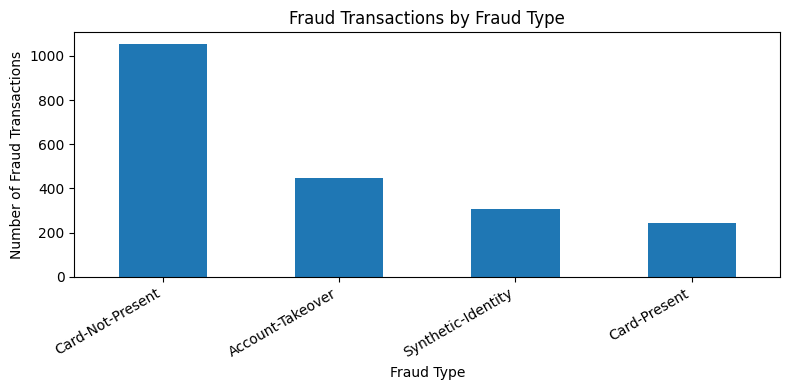

In [66]:
if "fraud_type" in clean_df.columns:
    fraud_only = clean_df[clean_df["is_fraud"] == 1].copy()

    fraud_type_summary = fraud_only["fraud_type"].value_counts().to_frame(
        "fraud_transactions"
    )
    fraud_type_summary["percentage_of_fraud"] = (
        fraud_type_summary["fraud_transactions"] /
        len(fraud_only) * 100
    )

    display(fraud_type_summary)

    fraud_type_summary["fraud_transactions"].plot(
        kind="bar", figsize=(8, 4),
        title="Fraud Transactions by Fraud Type"
    )
    plt.xlabel("Fraud Type")
    plt.ylabel("Number of Fraud Transactions")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## Step 27 — Fraud amount and labelled loss field

Compare transaction amount and `fraud_amount_lost` for fraud-labelled records.

Treat `fraud_amount_lost` as a dataset-provided outcome field, not a predictor. Check whether it is zero for legitimate transactions and whether it is populated only for fraud rows. Do not automatically assume it equals unrecovered bank loss until the field definition is verified.

In [67]:
if "fraud_amount_lost" in clean_df.columns:
    print("Fraud amount lost field by target class:")
    display(clean_df.groupby("is_fraud").agg(
        transaction_count=("transaction_id", "count"),
        total_fraud_amount_lost=("fraud_amount_lost", "sum"),
        average_fraud_amount_lost=("fraud_amount_lost", "mean"),
        total_transaction_amount=("transaction_amount", "sum")
    ))

    print("Fraud-labelled records with positive fraud_amount_lost:")
    display(
        clean_df.loc[
            (clean_df["is_fraud"] == 1) &
            (clean_df["fraud_amount_lost"] > 0),
            ["transaction_id", "transaction_amount", "fraud_amount_lost"]
        ].head(10)
    )

Fraud amount lost field by target class:


,transaction_count,total_fraud_amount_lost,average_fraud_amount_lost,total_transaction_amount
is_fraud,,,,
0,97945,0.000,0.000,"12,337,988.030"
1,2055,"279,842.200",136.176,"349,209.640"


Fraud-labelled records with positive fraud_amount_lost:


,transaction_id,transaction_amount,fraud_amount_lost
146,TXN-00000147,99.620,72.630
184,TXN-00000185,25.850,17.360
208,TXN-00000209,209.520,163.950
268,TXN-00000269,8.360,8.230
378,TXN-00000379,55.630,53.180
478,TXN-00000479,4.900,3.470
550,TXN-00000551,"1,099.740","1,016.230"
560,TXN-00000561,584.320,466.010
583,TXN-00000584,168.050,104.230
831,TXN-00000832,200.980,183.330


## Step 28 — Correlation analysis

Correlation helps identify numeric fields that move together. It does not prove causation.

We exclude identifier columns and the target-derived `fraud_amount_lost` field from this general numeric correlation view. `is_fraud` is included only as a descriptive target for comparing numeric associations.

,transaction_amount,transaction_hour,customer_age,account_age_days,credit_limit,credit_score,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,amount_vs_avg_ratio,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,is_fraud
transaction_amount,1.000,0.002,0.002,-0.002,0.002,-0.000,0.003,0.003,0.003,0.003,0.004,-0.005,-0.009,0.005,0.692,-0.000,0.001,-0.004,0.003,0.023
transaction_hour,0.002,1.000,-0.004,0.005,0.000,0.003,-0.001,-0.000,-0.002,-0.001,0.000,0.000,0.003,-0.002,0.001,-0.000,0.001,-0.003,0.000,-0.016
customer_age,0.002,-0.004,1.000,-0.001,-0.007,0.001,-0.002,-0.004,-0.002,-0.004,-0.003,-0.001,0.003,-0.003,-0.003,0.004,0.009,-0.004,0.004,0.005
account_age_days,-0.002,0.005,-0.001,1.000,-0.006,-0.000,0.001,0.001,0.003,0.000,0.003,0.000,-0.003,-0.001,-0.002,0.004,0.004,-0.006,0.000,-0.032
credit_limit,0.002,0.000,-0.007,-0.006,1.000,0.719,-0.003,-0.004,0.006,0.001,0.000,0.004,-0.001,-0.001,-0.001,0.005,0.002,-0.005,-0.013,-0.011
credit_score,-0.000,0.003,0.001,-0.000,0.719,1.000,0.000,-0.002,0.002,0.010,0.012,0.002,0.001,0.001,-0.003,0.020,0.016,-0.002,-0.017,-0.011
transactions_last_1h,0.003,-0.001,-0.002,0.001,-0.003,0.000,1.000,0.566,0.212,0.658,0.296,0.003,-0.003,0.004,0.005,-0.004,-0.005,-0.001,0.003,0.064
transactions_last_24h,0.003,-0.000,-0.004,0.001,-0.004,-0.002,0.566,1.000,0.370,0.372,0.536,-0.002,0.002,0.005,0.002,0.001,-0.000,-0.001,0.002,0.034
transactions_last_7d,0.003,-0.002,-0.002,0.003,0.006,0.002,0.212,0.370,1.000,0.140,0.195,0.001,-0.001,0.004,-0.001,-0.001,-0.001,-0.003,0.002,0.011
amount_last_1h,0.003,-0.001,-0.004,0.000,0.001,0.010,0.658,0.372,0.140,1.000,0.614,-0.001,-0.002,0.006,-0.055,0.371,0.346,-0.005,-0.010,0.043


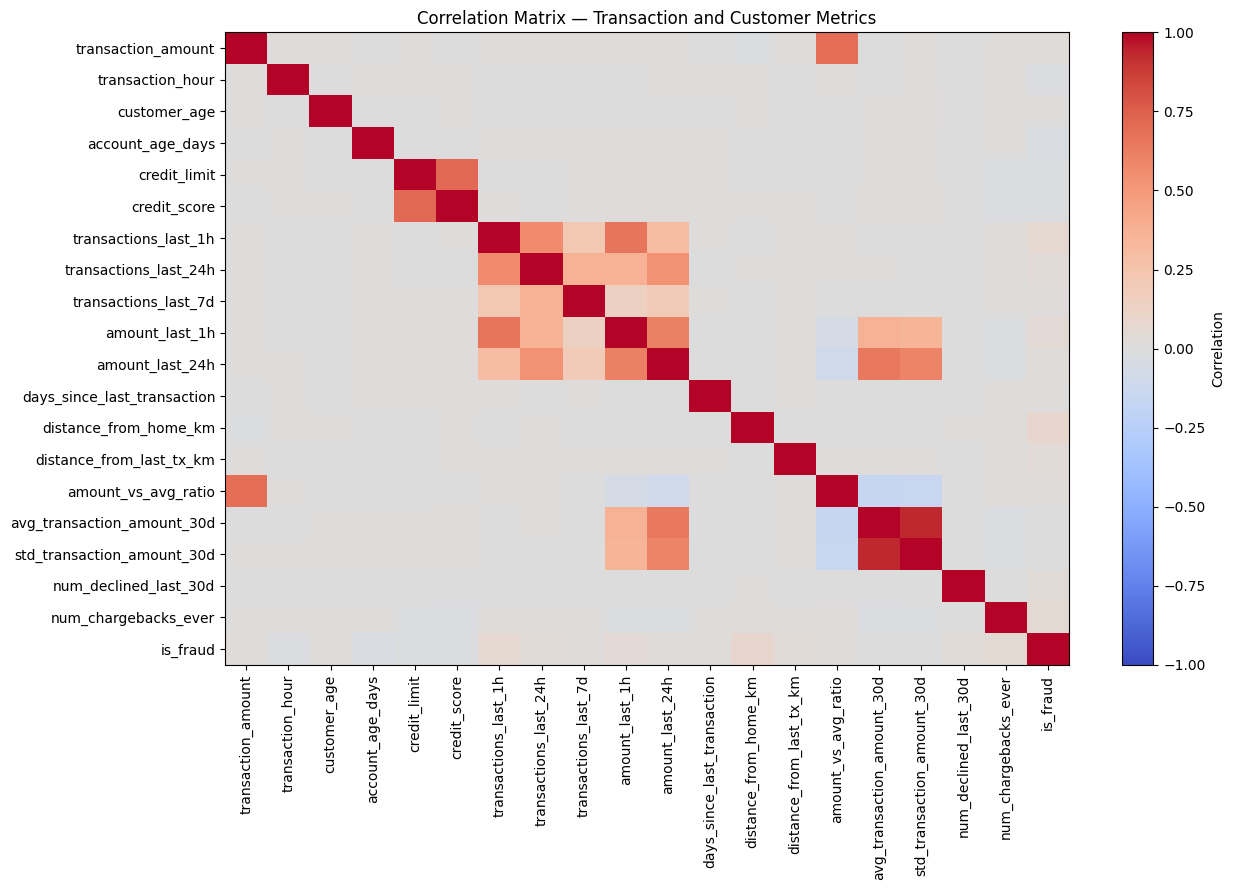

In [68]:
correlation_columns = [
    "transaction_amount",
    "transaction_hour",
    "customer_age",
    "account_age_days",
    "credit_limit",
    "credit_score",
    "transactions_last_1h",
    "transactions_last_24h",
    "transactions_last_7d",
    "amount_last_1h",
    "amount_last_24h",
    "days_since_last_transaction",
    "distance_from_home_km",
    "distance_from_last_tx_km",
    "amount_vs_avg_ratio",
    "avg_transaction_amount_30d",
    "std_transaction_amount_30d",
    "num_declined_last_30d",
    "num_chargebacks_ever",
    "is_fraud"
]

available_corr_columns = [
    column for column in correlation_columns if column in clean_df.columns
]

correlation_matrix = clean_df[available_corr_columns].corr(numeric_only=True)
display(correlation_matrix)

plt.figure(figsize=(13, 9))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)
plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)
plt.title("Correlation Matrix — Transaction and Customer Metrics")
plt.tight_layout()
plt.show()

## Step 29 — Create a final data-quality report

Review missing values, duplicates and data types after cleaning. This is useful evidence for the project report.

In [69]:
final_missing_report = pd.DataFrame({
    "missing_count": clean_df.isna().sum(),
    "missing_percent": clean_df.isna().sum() / len(clean_df) * 100
}).sort_values("missing_count", ascending=False)

final_quality_summary = pd.DataFrame({
    "check": [
        "total_rows",
        "total_columns",
        "exact_duplicate_rows_remaining",
        "duplicate_transaction_ids",
        "missing_cells_remaining",
        "fraud_transactions",
        "legitimate_transactions"
    ],
    "result": [
        len(clean_df),
        clean_df.shape[1],
        int(clean_df.duplicated().sum()),
        int(clean_df["transaction_id"].duplicated().sum())
            if "transaction_id" in clean_df.columns else np.nan,
        int(clean_df.isna().sum().sum()),
        int((clean_df["is_fraud"] == 1).sum())
            if "is_fraud" in clean_df.columns else np.nan,
        int((clean_df["is_fraud"] == 0).sum())
            if "is_fraud" in clean_df.columns else np.nan
    ]
})

display(final_quality_summary)
display(final_missing_report[final_missing_report["missing_count"] > 0])

,check,result
0,total_rows,100000
1,total_columns,54
2,exact_duplicate_rows_remaining,0
3,duplicate_transaction_ids,0
4,missing_cells_remaining,0
5,fraud_transactions,2055
6,legitimate_transactions,97945


,missing_count,missing_percent


## Step 30 — Export the cleaned data and EDA summaries

The outputs are saved in Kaggle's `/kaggle/working` folder. After the notebook finishes, use the Output panel to download them.

The cleaned file contains the derived analysis columns created above.

In [70]:
# Save cleaned transaction data
clean_df.to_csv(
    "/kaggle/working/credit_card_fraud_cleaned.csv",
    index=False
)
